## Linear Regression
- notebook runs in google colab no problem

### Importing libraries
All imports are in below cell

In [1]:
import pandas as pd
import numpy as np

from sklearn.linear_model import LinearRegression


import statsmodels.api as sm
import matplotlib.pyplot as plt

### Data Preprocessing

Download the dataset from Ucilnica and perform data preprocessing (e.g. handle
missing values).

In [2]:


# load data
data = pd.read_csv('podatki_PM.csv')

# * - preprocess data

# remove rows with missing values
# only 33 rows with NA out of total 1200
# so it's fine

row_cnt_before = data.shape[0]
data.dropna(inplace=True)
row_cnt_after = data.shape[0]

print(f"Number of rows before dropping NA: {row_cnt_before}")
print(f"Number of rows after dropping NA: {row_cnt_after}")
print(f"Percentage of rows dropped: {(row_cnt_before - row_cnt_after) / row_cnt_before * 100:.2f}%")


Number of rows before dropping NA: 1213
Number of rows after dropping NA: 1180
Percentage of rows dropped: 2.72%


### Linear Regression
Write a closed-form solution based algorithm for estimating multiple linear regression in Python.

In [ ]:
def linear_regression_matrix(X, y):
    # note that this expects X and y to be dataframe/series objects from pandas
    X = X.to_numpy()
    y = y.to_numpy()

    X_T = np.transpose(X)
    
    B = np.linalg.inv(X_T @ X) @ X_T @ y

    return B

#### Splitting dataset
Split the dataset into training and test subsets while removing the column named `Datum` from it. As the data is temporal do not perform random shuffle. Your target variable is `PM10`.


In [4]:

# drop 'Datum' column
data.drop(columns=['Datum'], inplace=True)

# extract target variable column
y = data['PM10']
X = data.drop(columns=['PM10'])

data_size = data.shape[0]
train_size = 0.8
train_data_size = int(train_size * data_size)


train_X = X.iloc[:train_data_size]
train_y = y.iloc[:train_data_size]

test_X = X.iloc[train_data_size:]
test_y = y.iloc[train_data_size:]


## Testing the model

In [5]:

#  call function for linear regression, then train and test model

# get matrix for linear
B = linear_regression_matrix(train_X, train_y)

test_y_pred = test_X.to_numpy() @ B

# compare predictions with actual
test_y_actual = test_y.to_numpy()

mse = np.mean((test_y_pred - test_y_actual) ** 2)

print(f"Mean Squared Error (MSE) on test set: {mse:.3f}")


Mean Squared Error (MSE) on test set: 70.090


### Comparison with SciKit-learn or 
Compare your implementation with the linear regression method available in either SciKit-learn or Statsmodels libraries.

In [6]:
# define and fit model

scikit_model = LinearRegression()

scikit_model.fit(train_X.to_numpy(), train_y.to_numpy())

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](10,)","[ 0.02,-3.31,-0.82,..., 0.54,-2.84, 1.05]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,51.14
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,10
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(10)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](10,)","[1271.12, 473.39, 307.73,..., 16.49, 9.26, 8.59]"


In [18]:
# test model
# print MSE value

scikit_test_y_pred = scikit_model.predict(test_X.to_numpy())

scikit_mse = np.mean((test_y_pred - test_y_actual) ** 2)

print(f"SciKit model MSE value: {scikit_mse:.3f}")
print(f"My model MSE value: {mse:.3f}")

SciKit model MSE value: 70.090
My model MSE value: 70.090


In [8]:
# compare coefficients

print("My model coefficients:")
print(B)

print("\nSciKit model coefficients:")
print(scikit_model.coef_)

print("\nDifference (my_model - scikit_model):")
print((B - scikit_model.coef_))

My model coefficients:
[ 0.09189516 -0.64875968 -0.37072822 -0.48083385  0.18117424  0.44527725
 -0.8945824   0.6149986  -0.65525628  3.78383659]

SciKit model coefficients:
[ 0.02395315 -3.30950086 -0.81643577 -0.20758987 -0.27592687  0.64982152
 -1.34377693  0.541207   -2.83963816  1.04559383]

Difference (my_model - scikit_model):
[ 0.067942    2.66074118  0.44570755 -0.27324397  0.45710111 -0.20454427
  0.44919453  0.0737916   2.18438188  2.73824276]


## Diagnostics
Diagnose your linear regression using diagnostic plots introduced in Lecture 2. You can use the Statsmodels library.

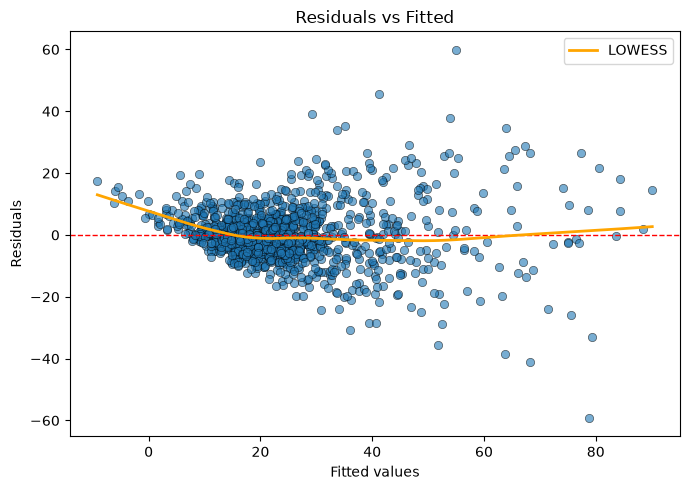

In [ ]:


# residuals vs fitted plot

fitted = X.to_numpy() @ B
residuals = y.to_numpy() - fitted

fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(fitted, residuals, alpha=0.6, edgecolor="k", linewidth=0.5)
ax.axhline(0, color="red", linestyle="--", linewidth=1)

# Optional LOWESS smoother
lowess = sm.nonparametric.lowess(residuals, fitted, frac=2/3)
ax.plot(lowess[:, 0], lowess[:, 1], color="orange", linewidth=2, label="LOWESS")

ax.set_xlabel("Fitted values")
ax.set_ylabel("Residuals")
ax.set_title("Residuals vs Fitted")
ax.legend()
plt.tight_layout()
plt.show()

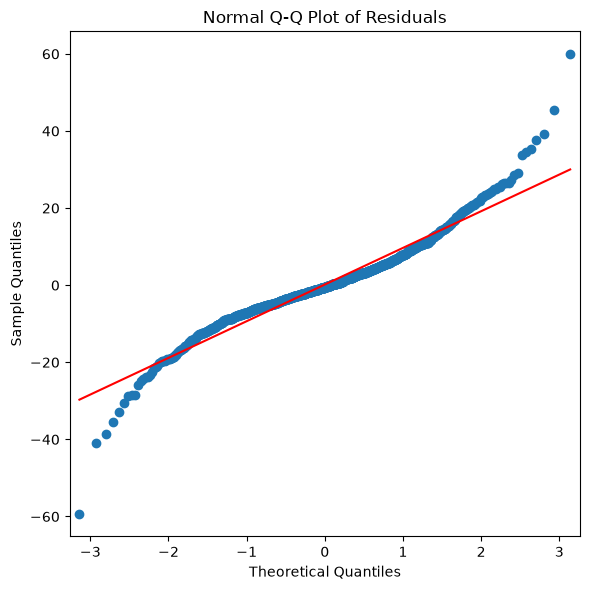

In [10]:
# normal q-q plot
fig, ax = plt.subplots(figsize=(6, 6))
sm.qqplot(residuals, line="s", ax=ax)   # "s" = line based on std dev and mean
ax.set_title("Normal Q-Q Plot of Residuals")
plt.tight_layout()
plt.show()

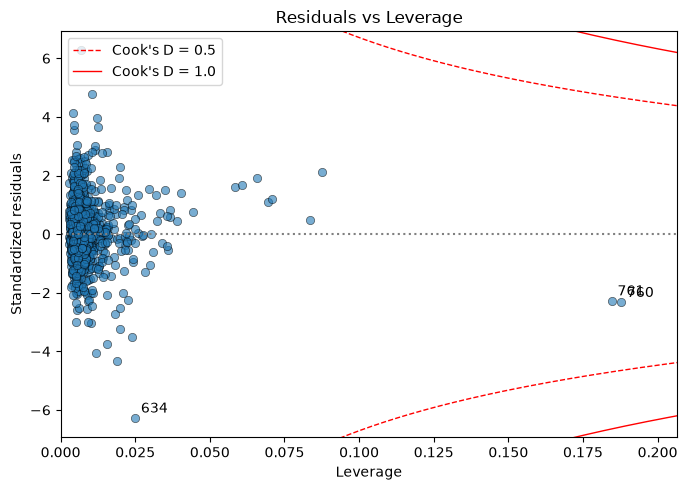

In [11]:
# Leverage (same formula, just with X in place of X_design)
XtX_inv = np.linalg.inv(X.T @ X)
h = np.einsum("ij,jk,ik->i", X, XtX_inv, X)
n, p = X.shape


# Standardized (internally studentized) residuals
s2 = residuals @ residuals / (n - p)
std_resid = residuals / np.sqrt(s2 * (1 - h))

# Cook's distance
cooks = (std_resid**2 / p) * (h / (1 - h))


# Plot
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(h, std_resid, alpha=0.6, edgecolor="k", linewidth=0.5)
ax.axhline(0, color="grey", linestyle=":")

# Cook's distance contours (D = 0.5 and D = 1)
hx = np.linspace(1e-3, h.max() * 1.1, 200)
for c, ls in [(0.5, "--"), (1.0, "-")]:
    curve = np.sqrt(c * p * (1 - hx) / hx)
    ax.plot(hx, curve, color="red", linestyle=ls, linewidth=1, label=f"Cook's D = {c}")
    ax.plot(hx, -curve, color="red", linestyle=ls, linewidth=1)

# Label the 3 most influential points
for i in np.argsort(cooks)[-3:]:
    ax.annotate(str(i), (h[i], std_resid[i]), xytext=(4, 4), textcoords="offset points")

ymax = max(3.5, np.abs(std_resid).max() * 1.1)
ax.set_ylim(-ymax, ymax)
ax.set_xlim(0, h.max() * 1.1)
ax.set_xlabel("Leverage")
ax.set_ylabel("Standardized residuals")
ax.set_title("Residuals vs Leverage")
ax.legend()
plt.tight_layout()
plt.show()

<Figure size 800x600 with 0 Axes>

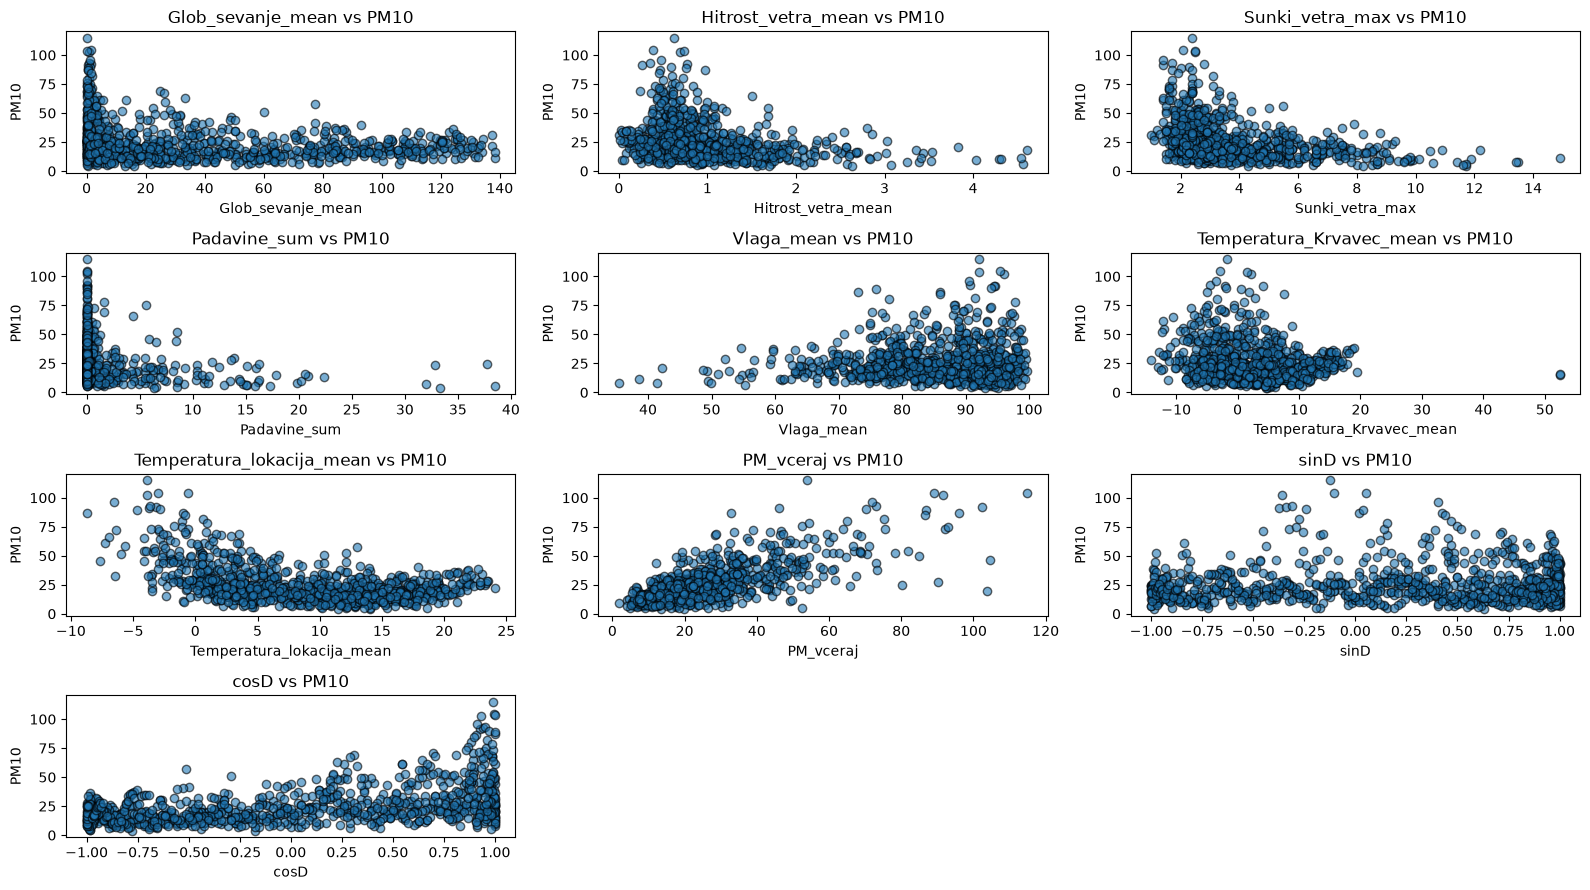

In [12]:
# Plot each feature against the target variable
# to see what kind of transformation might be useful for each feature
# to get a more linear relationship with the target variable

plt.figure(figsize=(8, 6))
fig, axes = plt.subplots(4, 3, figsize=(16, 9))
axes = axes.flatten()


for i, col in enumerate(train_X.columns):
    axes[i].scatter(train_X[col], train_y, alpha=0.6, edgecolor="k", linewidth=1)
    axes[i].set_xlabel(col)
    axes[i].set_ylabel("PM10")
    axes[i].set_title(f"{col} vs PM10")

# Hide the two unused grid cells
for ax in axes[len(train_X.columns):]:
    ax.set_visible(False)


fig.tight_layout()
plt.show()

## Extra transformations of columns
Write code to add polinomial transformations of attributes, and the logarithmic or square root transformations of the target.


In [13]:

# - 3 functions polynomial, logarithmic, square root

# * below 3 functions add a new column
# * there are more below which modify column directly
def add_polynomial_col(df_X, col_name, power = 2):
    # by default column value is squared
    newcol_name = f"{col_name}^{power}"
    df_X[newcol_name] = df_X[col_name] ** power
    # print(f"Added polynomial column: {newcol_name}")
    return newcol_name

def add_log_col(df_X, col_name):
    # using log2
    newcol_name = f"{col_name}_log2"
    df_X[newcol_name] = np.log2(df_X[col_name])
    return newcol_name

def add_sqrt_col(df_X, col_name):
    return add_polynomial_col(df_X, col_name, 0.5)


# * BELOW function modify column values directly
def transform_to_polynomial(df_X, col_name, power=2):
    df_X[col_name] = np.power(df_X[col_name], power)

def transform_to_log(df_X, col_name):
    df_X[col_name] = np.log2(df_X[col_name])

def transform_to_sqrt(df_X, col_name):
    df_X[col_name] = np.sqrt(df_X[col_name])

### Plotting the transformed version of each column

c:\Users\Lenovo\AppData\Local\Python\pythoncore-3.15-64\Lib\site-packages\pandas\core\arraylike.py:402: RuntimeWarning: divide by zero encountered in log2
  result = getattr(ufunc, method)(*inputs, **kwargs)
c:\Users\Lenovo\AppData\Local\Python\pythoncore-3.15-64\Lib\site-packages\pandas\core\arraylike.py:402: RuntimeWarning: invalid value encountered in log2
  result = getattr(ufunc, method)(*inputs, **kwargs)


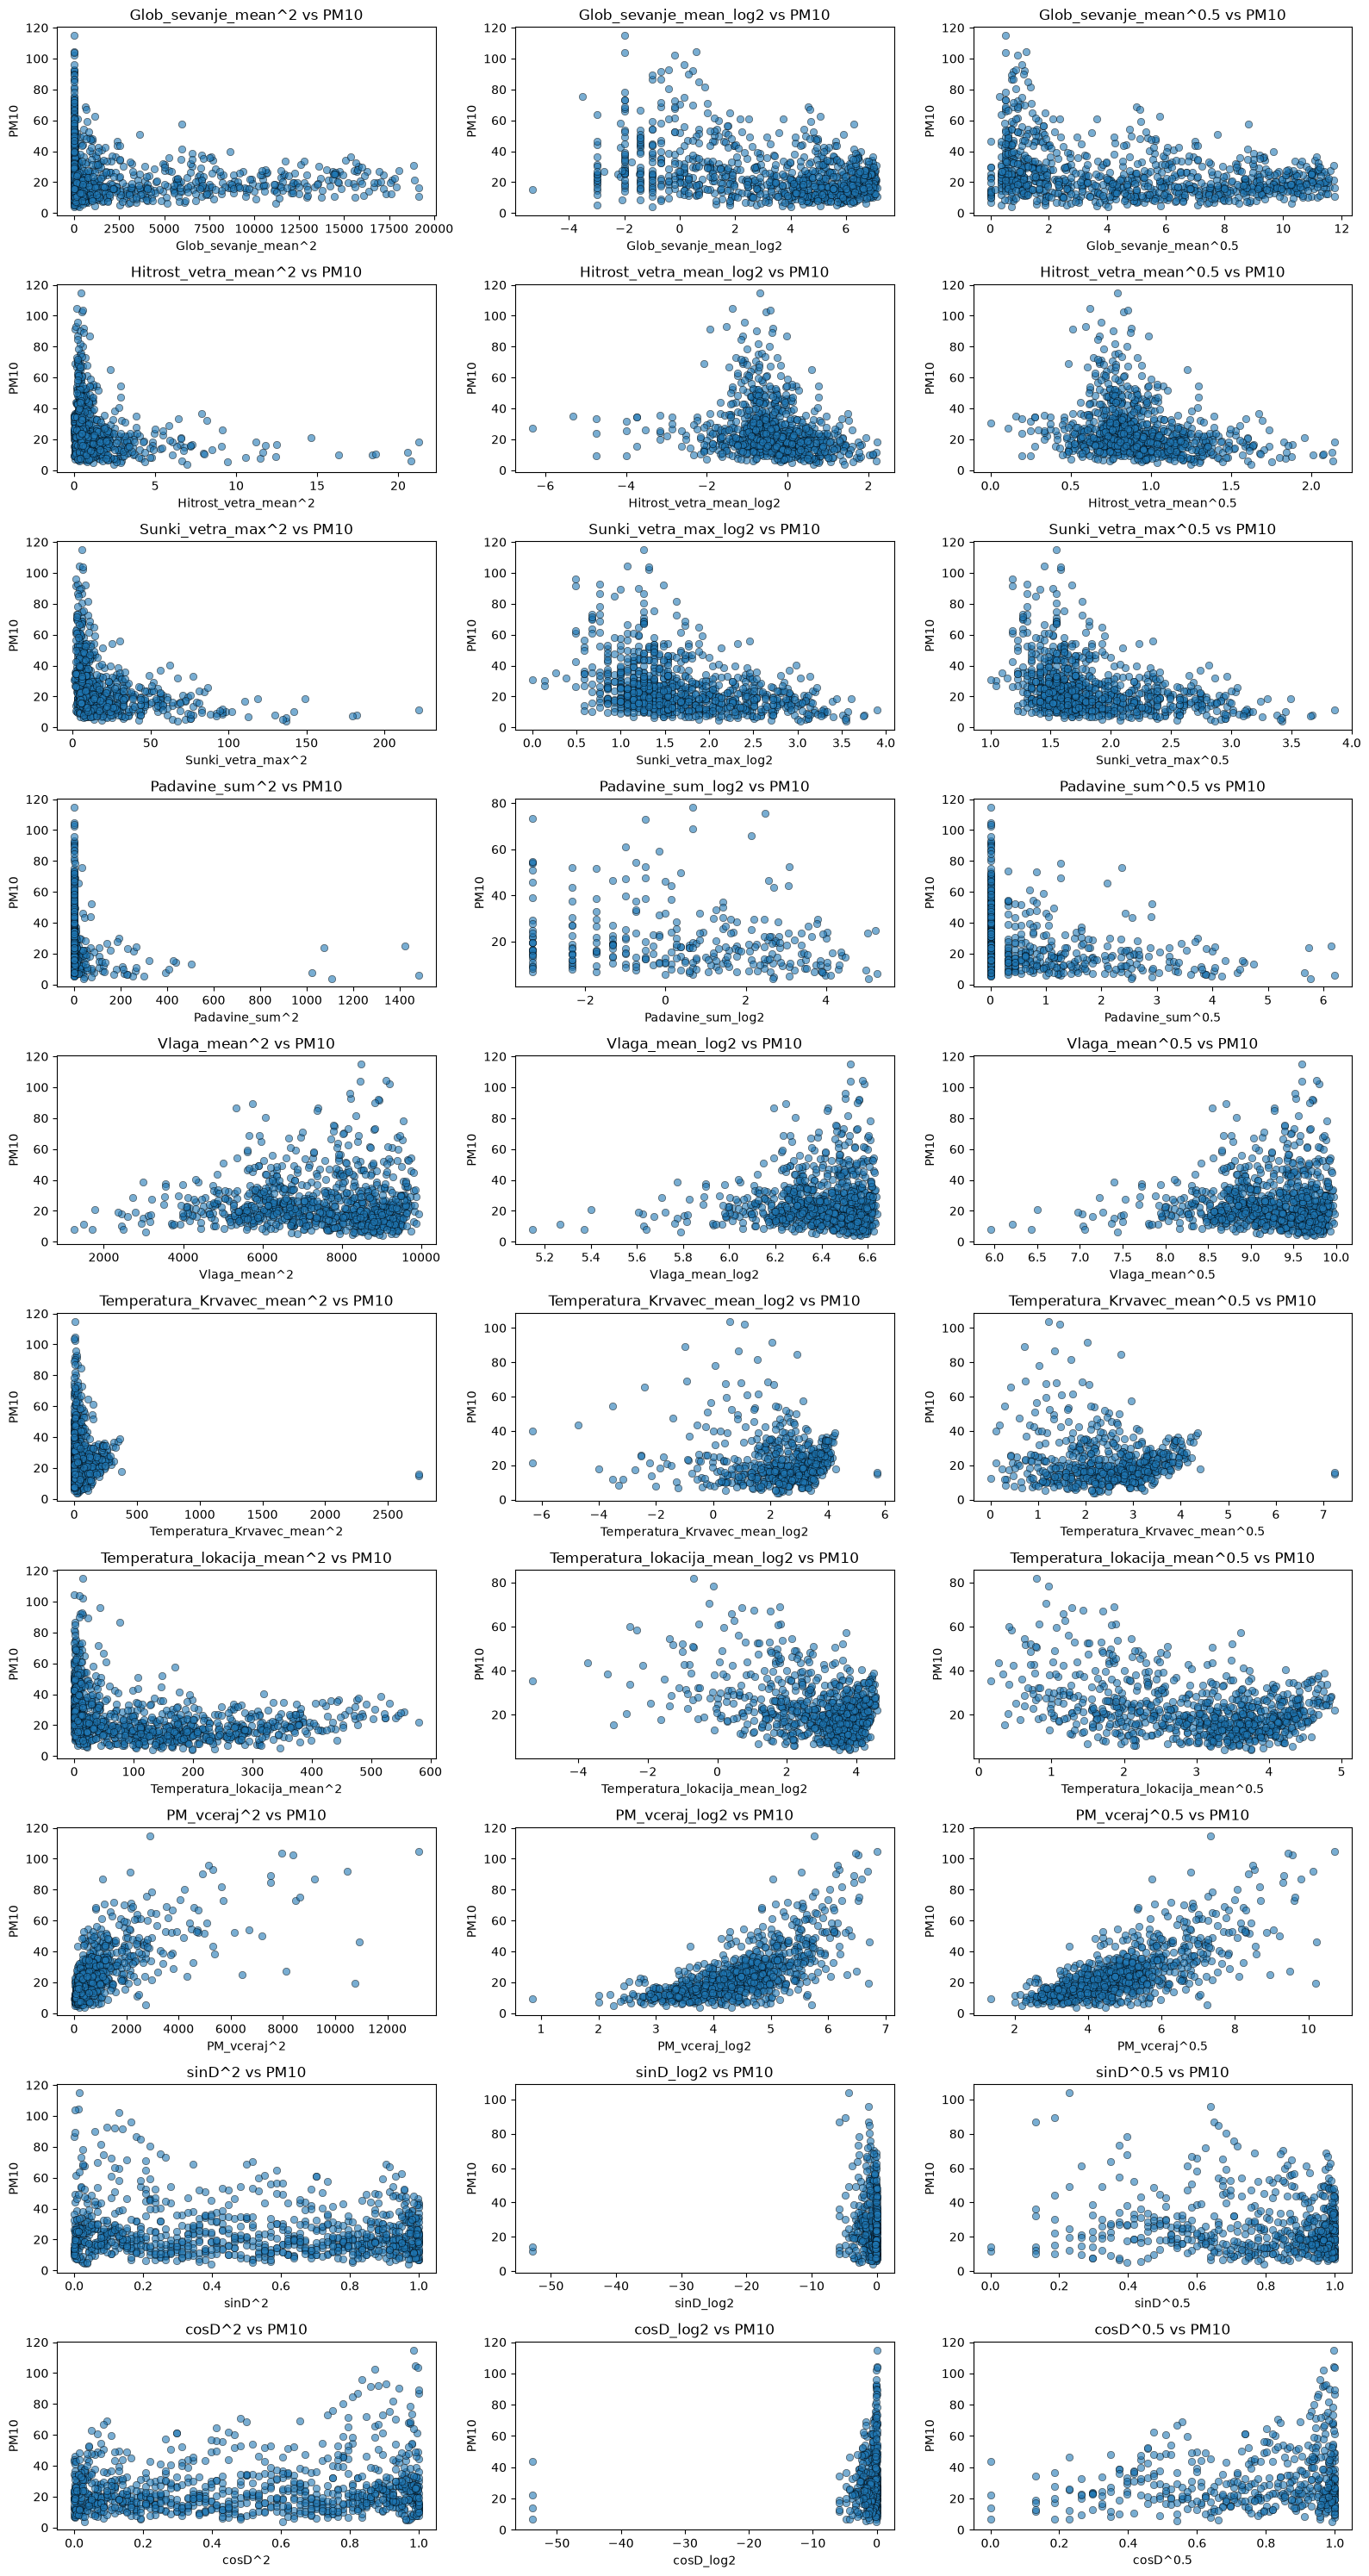

In [14]:

# * done on copy of TRAIN data
DUP_train_X = train_X.copy()
new_cols = []
for col in train_X.columns:
    # print(f"Adding polynomial, log, and sqrt columns for {col}...")
    c1 = add_polynomial_col(DUP_train_X, col, 2)
    c2 = add_log_col(DUP_train_X, col)
    c3 = add_sqrt_col(DUP_train_X, col)
    # print(f"Added columns: {c1}, {c2}, {c3}")
    new_cols.append(c1)
    new_cols.append(c2)
    new_cols.append(c3)


fig, axes = plt.subplots(10, 3, figsize=(16, 30))
axes = axes.flatten()


for i, col in enumerate(new_cols):
    axes[i].scatter(DUP_train_X[col], train_y, alpha=0.6, edgecolor="k", linewidth=0.5)
    axes[i].set_xlabel(col)
    axes[i].set_ylabel("PM10")
    axes[i].set_title(f"{col} vs PM10")

fig.tight_layout()
plt.show()

### Choosing which transformed columns to keep based on above plots

**Note**

Below cell checks what percentage of a column has negative, positive and 0 values.
Had to do this, since if some column has negative values it introduces `NaN`s when applied square root (sqrt is defined only on values `>=0`).
Also some columns looked like they had a lot of `0` values, but after actually checking, only one (`Padavine_sum`) has 70% of values equal to 0, and the rest looking like that have lots of values close to `0` but few actually `0`.

In [15]:
# see what percentage of column values is > 0 for every column
print("(Percentage > 0, percentage = 0, percentage < 0)")
for col in train_X.columns:
    pos_count = (train_X[col] > 0).sum()
    zero_count = ((train_X[col]) == 0).sum()
    neg_count = (train_X[col] < 0).sum()
    total_count = train_X.shape[0]
    pos_percentage = (pos_count / total_count) * 100
    zero_percentage = (zero_count / total_count) * 100
    neg_percentage = (neg_count / total_count) * 100
    print(f"Column '{col}':\n\t({pos_percentage:.2f}%, {zero_percentage:.2f}%, {neg_percentage:.2f}%)")

(Percentage > 0, percentage = 0, percentage < 0)
Column 'Glob_sevanje_mean':
	(98.20%, 1.80%, 0.00%)
Column 'Hitrost_vetra_mean':
	(99.89%, 0.11%, 0.00%)
Column 'Sunki_vetra_max':
	(100.00%, 0.00%, 0.00%)
Column 'Padavine_sum':
	(29.66%, 70.34%, 0.00%)
Column 'Vlaga_mean':
	(100.00%, 0.00%, 0.00%)
Column 'Temperatura_Krvavec_mean':
	(64.62%, 0.11%, 35.28%)
Column 'Temperatura_lokacija_mean':
	(88.98%, 0.00%, 11.02%)
Column 'PM_vceraj':
	(100.00%, 0.00%, 0.00%)
Column 'sinD':
	(62.71%, 0.00%, 37.29%)
Column 'cosD':
	(49.68%, 0.00%, 50.32%)


In [ ]:

train_X_modified = train_X.copy()
test_X_modified = test_X.copy()


transform_to_polynomial(train_X_modified, 'Temperatura_Krvavec_mean', 2)
transform_to_polynomial(train_X_modified, 'Glob_sevanje_mean', 2)
train_X_modified.drop(columns=['Padavine_sum'], inplace=True)


transform_to_polynomial(test_X_modified, 'Temperatura_Krvavec_mean', 2)
transform_to_polynomial(test_X_modified, 'Glob_sevanje_mean', 2)
test_X_modified.drop(columns=['Padavine_sum'], inplace=True)

# print("Any NaN values in column cosD after transformation:", np.isnan(train_X_modified['cosD'].to_numpy()).any())
print("Any NaN values in column Temperatura_Krvavec_mean after transformation:", np.isnan(train_X_modified['Temperatura_Krvavec_mean'].to_numpy()).any())
# print("Any NaN values in column Padavine_sum after transformation:", np.isnan(train_X_modified['Padavine_sum'].to_numpy()).any())

print(f"Any NaN values in column Temperatura_Krvavec_mean after transformation (test set): {np.isnan(test_X_modified['Temperatura_Krvavec_mean'].to_numpy()).any()}")
# print(f"Any NaN values in column Padavine_sum after transformation (test set): {np.isnan(test_X_modified['Padavine_sum'].to_numpy()).any()}")



# below are comments, notes for some columns

# - cosD - no new col
# - sinD - no new col
# - PM_vceraj - kinda already is linear, new cols are less - so no new col
# - Temperatura_lokacija_mean - no new col
# 	- tons of values CLOSE to 0, but none actually zero
# 	- most linear look as it is
# - Temperature_Krvavec_mean - polynomial ^2 col
# 	- also tons values close to 0, few actually zero
# 	- but better look in ^2 - linear-wise
# - Vlaga_mean - no new col
# - Padavine_sum - remove col
# 	- 70% of values are 0
# - Sunki_vetra_max - no new col
# - Hitrost_vetra_mean - no new col
# - Glob_sevanje_mean - no new col
# 	- maybe polynomial ^2 is option
#   - but looks more linear as it is



Any NaN values in column Temperatura_Krvavec_mean after transformation: False
Any NaN values in column Temperatura_Krvavec_mean after transformation (test set): False


### Refitting linear regression with transformed columns

In [17]:

B_modified = linear_regression_matrix(train_X_modified, train_y)

mse_modified = np.mean((test_X_modified.to_numpy() @ B_modified - test_y.to_numpy()) ** 2)

print(f"Mean Squared Error (MSE) on test set before transformations: {mse:.3f}")
print(f"Mean Squared Error (MSE) on test set after transformations: {mse_modified:.3f}")

Mean Squared Error (MSE) on test set before transformations: 70.090
Mean Squared Error (MSE) on test set after transformations: 75.368


## Comment on the results

#### **Diagnostics**
Residuals plot shows a very high concentration in the middle, then the values start to scatter seeming like the variance is heteroscedastic. However I don't think there are enough samples here to prove heteroscedasticity.

The Q-Q normal plot shows us that the graph is mostly linear, curving a bit at the extremees.

When we plot residuals vs leverage, we can see there are only a few outliers (2-3), most of the samples being concentrated.

The rest of the plots, plotting attributes vs target variable and transformed attributes vs target variables were depicted to show whether a relationship is linear and would it be better to apply a transformation or not.


#### **Transformations**
Trying out transformations based on eyeballing the transformed column vs target variable is not an efficient way to actually improve MSE (loss function) value.

Also removing a column with 70% of values equal to 0 (`Padavine_sum`) did not help improve the MSE value of linear regression either.